In [ ]:

from google.colab import files

uploaded = files.upload()


Saving gender_submission.csv to gender_submission (1).csv
Saving test.csv to test (1).csv
Saving train.csv to train (1).csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")

print("Training dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)

display(train_df.head())

Training dataset shape: (891, 12)
Testing dataset shape: (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
print("Column names:")
print(train_df.columns.tolist())

print("\nDataset information:")
train_df.info()

print("\nMissing values:")
display(train_df.isnull().sum())

print("\nStatistical summary:")
display(train_df.describe())

Column names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Missing values:


,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0



Statistical summary:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


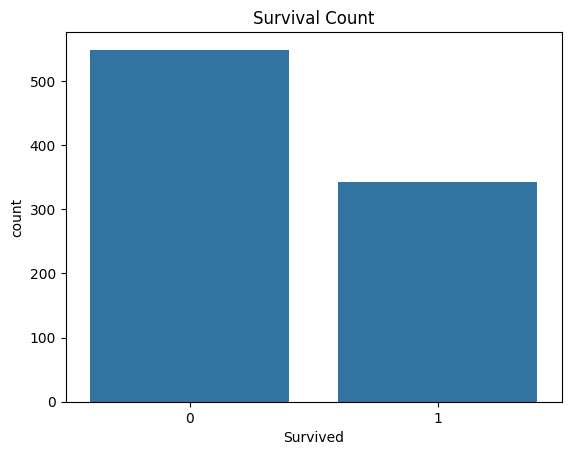

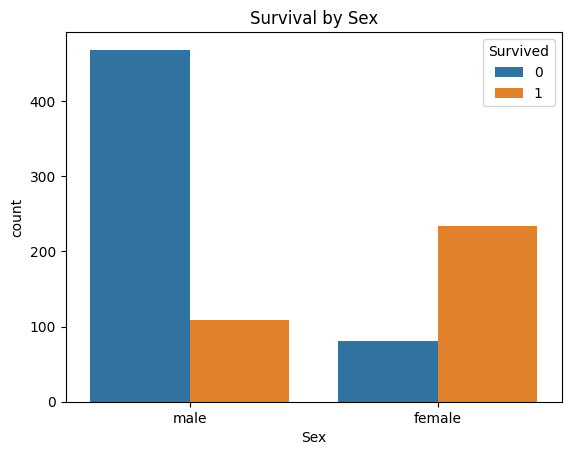

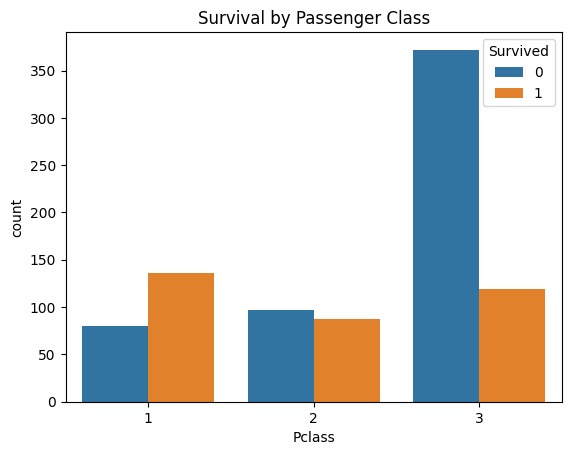

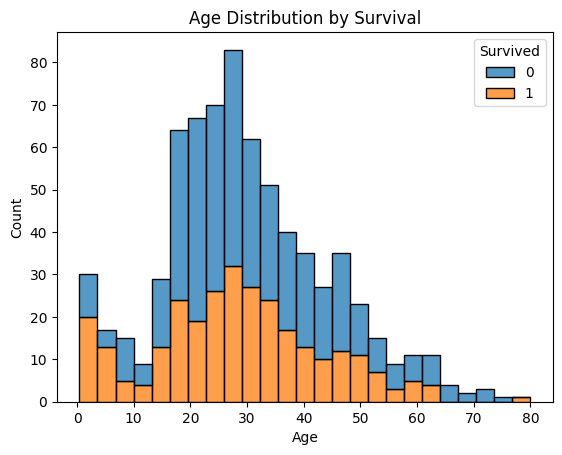

In [ ]:
sns.countplot(data=train_df, x="Survived")
plt.title("Survival Count")
plt.show()

sns.countplot(
    data=train_df,
    x="Sex",
    hue="Survived"
)
plt.title("Survival by Sex")
plt.show()

sns.countplot(
    data=train_df,
    x="Pclass",
    hue="Survived"
)
plt.title("Survival by Passenger Class")
plt.show()

sns.histplot(
    data=train_df,
    x="Age",
    hue="Survived",
    bins=25,
    multiple="stack"
)
plt.title("Age Distribution by Survival")
plt.show()

In [ ]:
features = [
    "Pclass",
    "Sex",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked"
]

X = train_df[features]
y = train_df["Survived"]

X_test_final = test_df[features]

print("Features prepared.")
print("Input shape:", X.shape)
print("Target shape:", y.shape)

Features prepared.
Input shape: (891, 7)
Target shape: (891,)


In [ ]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))

Training rows: 712
Validation rows: 179


In [ ]:
numeric_features = [
    "Pclass", "Age", "SibSp", "Parch", "Fare"
]

categorical_features = ["Sex", "Embarked"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


Validation accuracy: 81.56%

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.89      0.86       110
           1       0.80      0.70      0.74        69

    accuracy                           0.82       179
   macro avg       0.81      0.79      0.80       179
weighted avg       0.81      0.82      0.81       179



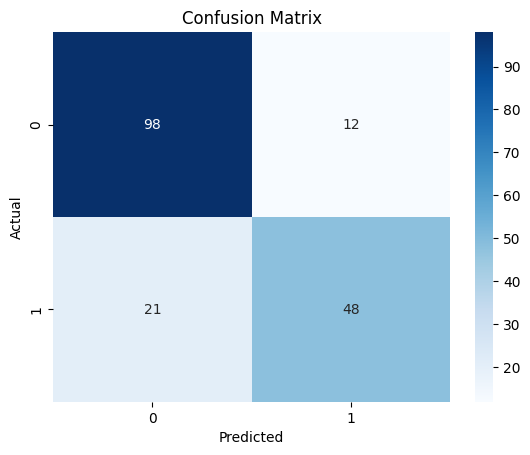

In [ ]:
y_pred = model.predict(X_val)

accuracy = accuracy_score(y_val, y_pred)

print(f"Validation accuracy: {accuracy:.2%}")

print("\nClassification Report:")
print(classification_report(y_val, y_pred))

cm = confusion_matrix(y_val, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
model.fit(X, y)

test_predictions = model.predict(X_test_final)

submission = pd.DataFrame({
    "PassengerId": test_df["PassengerId"],
    "Survived": test_predictions
})

display(submission.head())

print("Prediction counts:")
print(submission["Survived"].value_counts())

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,1
4,896,1


Prediction counts:
Survived
0    264
1    154
Name: count, dtype: int64


In [ ]:
submission.to_csv(
    "titanic_predictions.csv",
    index=False
)

print("Prediction file created successfully!")

Prediction file created successfully!


In [ ]:
from google.colab import files

files.download("titanic_predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
new_passenger = pd.DataFrame([{
    "Pclass": 3,
    "Sex": "female",
    "Age": 22,
    "SibSp": 0,
    "Parch": 0,
    "Fare": 7.25,
    "Embarked": "S"
}])

prediction = model.predict(new_passenger)[0]

if prediction == 1:
    print("Prediction: Passenger may have survived.")
else:
    print("Prediction: Passenger may not have survived.")

Prediction: Passenger may have survived.


In [ ]:

from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


In [ ]:

import os
import shutil

project_folder = "/content/drive/MyDrive/Titanic_Survival_Prediction"
os.makedirs(project_folder, exist_ok=True)

for filename in [
    "titanic_model.pkl",
    "titanic_predictions.csv",
    "TitanicSurvival_Prediction.ipynb"
]:
    if os.path.exists(filename):
        shutil.copy2(
            filename,
            os.path.join(project_folder, filename)
        )

print("Available project files copied to Google Drive.")


Available project files copied to Google Drive.
